 # Attack-Resistant Multi-Class Malicious URL Detection Using Machine Learning

## Problem Statement

 **Detection models can be fooled.** ML models flag malicious URLs, but small, harmless-to-the-attacker changes (extra digits, subdomains, a longer path) can make a dangerous URL look "safe". Most detectors are never tested against such modified URLs.

 **Accuracy hides weak detection of rare threats.** The data is imbalanced (about 67% benign, only about 4% malware), so a model can score high accuracy while missing most malware. Macro-F1 and per-class results are needed instead.

 **Black-box models give no reasons.** Users and analysts cannot see why a URL was flagged, which makes the model hard to trust, debug or improve.

## About the Project



- **What it is:** An ML system that classifies a URL as benign, defacement, phishing or malware.
- **Why it is needed:** Malicious URLs are hard to spot, and ML detectors can be fooled by small URL changes.
- **Data:** 651,191 URLs with 64 columns of URL, host, web and phishing-keyword features.
- **How it works:** A Random Forest is trained on cleaned data, with class weights for the imbalance.
- **Tuning:** Manual, Grid, Random, Bayesian and Hyperband search are compared.
- **Attack resistance:** It is tested on attacker-modified URLs and retrained with them.
- **Strengths:** It detects new URLs, runs fast and explains each verdict.

## Proposed System



- The proposed system cleans the URL dataset and trains a class-weighted Random Forest, tuned through Manual, Grid, Random, Bayesian and Hyperband search, to classify each URL as benign, defacement, phishing or malware.
- Performance is judged by macro-averaged F1-score and per-class recall instead of accuracy alone, so that rare threats such as malware are not overlooked.
- To achieve attack resistance, the model is tested on attacker-modified URLs (extra digits, subdomains and longer paths) and retrained with them to reduce how often it is deceived.
- Feature-importance analysis explains each decision, and because the model uses features computed directly from the URL, it can classify unseen URLs in real time without blacklists.

# Import Libraries

Before loading the data, import the essential Python libraries required for data manipulation and visualization

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

# Load Dataset
we load the **Malicious URL Detection** dataset

In [3]:
df = pd.read_csv(r"e:\Rezilyen intern\Data set\Malicious URL Detection Dataset\final_dataset_with_all_features_v3.1.csv")
df.head()


,url,type,label,url_len,@,?,-,=,.,#,...,phish_adv_long_domain,phish_adv_many_subdomains,phish_adv_encoded_chars,phish_adv_path_keywords,phish_adv_has_redirect,phish_adv_many_params,path_has_hacked_terms,suspicious_extension,path_underscore_count,is_gov_edu
0,br-icloud.com.br,phishing,2,16,0,0,1,0,2,0,...,0,0,0,0,0,0,0,0,0,0
1,mp3raid.com/music/krizz_kaliko.html,benign,0,35,0,0,0,0,2,0,...,0,0,0,0,0,0,0,1,1,0
2,bopsecrets.org/rexroth/cr/1.htm,benign,0,31,0,0,0,0,2,0,...,0,0,0,0,0,0,0,1,0,0
3,http://garage-pirenne.be/index.php?option=com_...,defacement,1,84,0,1,1,4,2,0,...,0,0,0,0,0,3,0,1,0,0
4,http://adventure-nicaragua.net/index.php?optio...,defacement,1,235,0,1,1,3,2,0,...,0,0,0,0,0,2,0,1,0,0


 # Data Cleaning & Feature Selection
  Feature Selection & Dropping Unwanted Columns, Handling Missing & Null Values, Duplicate Removal

In [4]:
# 1. Define the exact columns you want to keep
selected_columns = [
    # Target
    'type',
    'label',
    
    # Strongest clues
    'having_ip_address',
    'abnormal_url',
    '//',
    'https',
    'url_len',
    'digits',
    'suspicious_extension',
    
    # Phishing indicators
    '-',
    'phish_urgency_words',
    'phish_brand_hijack'
]

# (Optional) If you also want to include the web_* features:
# web_features = [col for col in df.columns if col.startswith('web_')]
# selected_columns += web_features

# 2. Filter the dataframe to keep ONLY these columns
df_filtered = df[selected_columns].copy()

# 3. Separate into Features (X) and Target (y) for Machine Learning
y = df_filtered['label']
X = df_filtered.drop(columns=['type', 'label'])

# 4. View results
print(f"Dataset shape with selected features: {df_filtered.shape}")
print(f"Features (X) shape:                   {X.shape}")
print(f"Target (y) shape:                     {y.shape}")

df_filtered.head()


Dataset shape with selected features: (651191, 12)
Features (X) shape:                   (651191, 10)
Target (y) shape:                     (651191,)


,type,label,having_ip_address,abnormal_url,//,https,url_len,digits,suspicious_extension,-,phish_urgency_words,phish_brand_hijack
0,phishing,2,0,1,0,0,16,0,0,1,0,0
1,benign,0,0,1,0,0,35,1,1,0,0,0
2,benign,0,0,1,0,0,31,1,1,0,0,0
3,defacement,1,0,0,1,0,84,7,1,1,0,0
4,defacement,1,0,0,1,0,235,22,1,1,0,0


In [5]:
# Check count of missing values per column
df.isna().sum()

url                      0
type                     0
label                    0
url_len                  0
@                        0
                        ..
phish_adv_many_params    0
path_has_hacked_terms    0
suspicious_extension     0
path_underscore_count    0
is_gov_edu               0
Length: 64, dtype: int64

In [6]:
# Check total null values in the entire dataset
print("Total Null Values:", df.isnull().sum().sum())


Total Null Values: 12223


In [7]:
# To Just Remove (Drop) the Null Values
df = df.dropna().reset_index(drop=True)
print("Total Null Values:", df.isnull().sum().sum())


Total Null Values: 0


In [8]:
# Check total duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 509


In [9]:
df = df.drop_duplicates(subset=['url'], keep='first').reset_index(drop=True)
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


### Total Statistics: overall mean, median, mode and standard deviation of all numeric features (excluding label)

In [ ]:
# Combine all numeric columns into one 1D array
values = df.select_dtypes(include='number').to_numpy().flatten()
values = values[~np.isnan(values)]  # remove any NaNs

mean   = values.mean()
median = np.median(values)
mode   = pd.Series(values).mode()[0]
sd     = values.std(ddof=1)

print("Total Mean   :", round(mean, 2))
print("Total Median :", median)
print("Total Mode   :", mode)
print("Total SD     :", round(sd, 2))


Total Mean   : 2.88
Total Median : 0.0
Total Mode   : 0.0
Total SD     : 21.4


### Line Chart: URL length vs type, number of URLs of each type (benign, defacement, phishing, malware) at each URL length

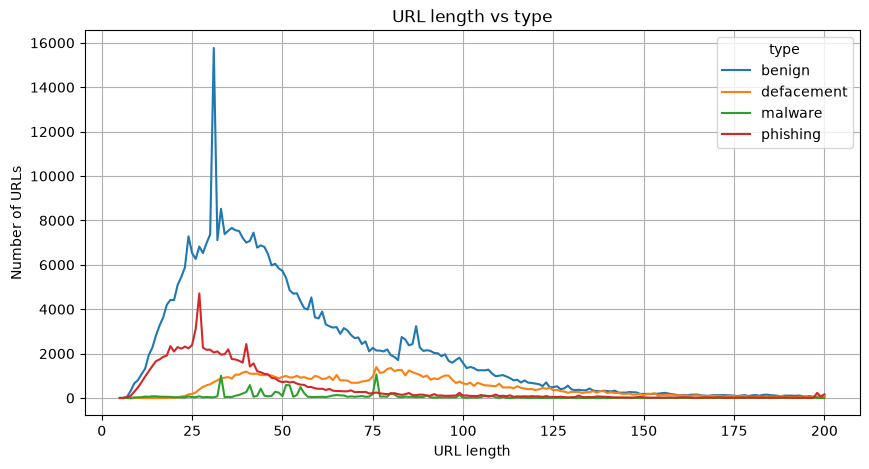

In [14]:
# Replace 'df_cleaned' with 'df'
data = df[['url_len', 'type']]
data = data[data['url_len'] <= 200]

counts = data.groupby(['url_len', 'type']).size().unstack(fill_value=0)

counts.plot(kind='line', figsize=(10, 5))
plt.xlabel('URL length')
plt.ylabel('Number of URLs')
plt.title('URL length vs type')
plt.grid(True)
plt.show()


### Bar Charts: number of URLs per type (class imbalance), and % of URLs having each trait (raw IP address, HTTPS, abnormal URL, suspicious extension) by type

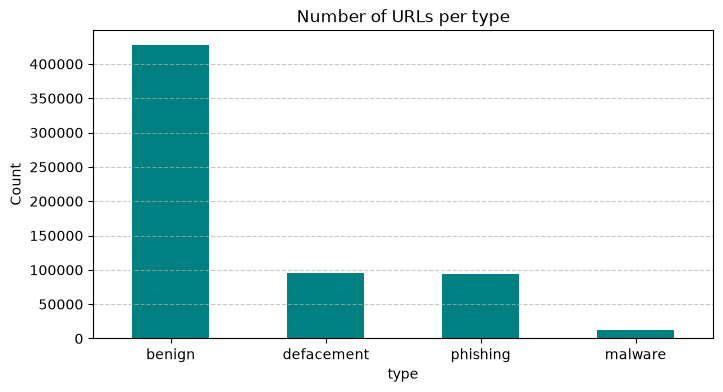

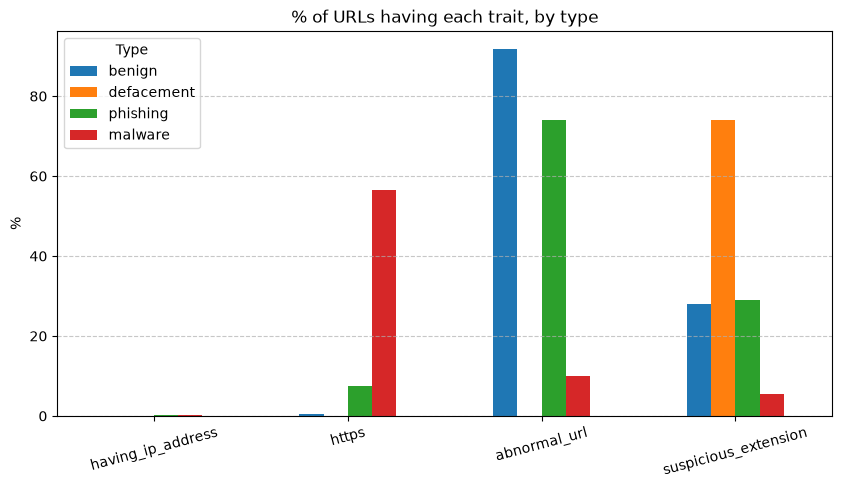

In [16]:

# If df_cleaned is not defined, fall back to df
if 'df_cleaned' not in locals():
    df_cleaned = df

order = ['benign', 'defacement', 'phishing', 'malware']

# Bar 1: counts
df_cleaned['type'].value_counts().reindex(order).plot(kind='bar', figsize=(8, 4), color='teal')
plt.title('Number of URLs per type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Bar 2: traits
traits = ['having_ip_address', 'https', 'abnormal_url', 'suspicious_extension']

# Only pick traits that exist in the dataframe
available_traits = [t for t in traits if t in df_cleaned.columns]

if available_traits:
    (df_cleaned.groupby('type')[available_traits].mean() * 100).reindex(order).T.plot(kind='bar', figsize=(10, 5))
    plt.title('% of URLs having each trait, by type')
    plt.ylabel('%')
    plt.xticks(rotation=15)
    plt.legend(title='Type')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print(f"None of the traits {traits} were found in df_cleaned columns.")


### Scatter Plot: URL length vs number of digits (log scale), coloured by type. Digits grow with length, and malware has more digits at the same length

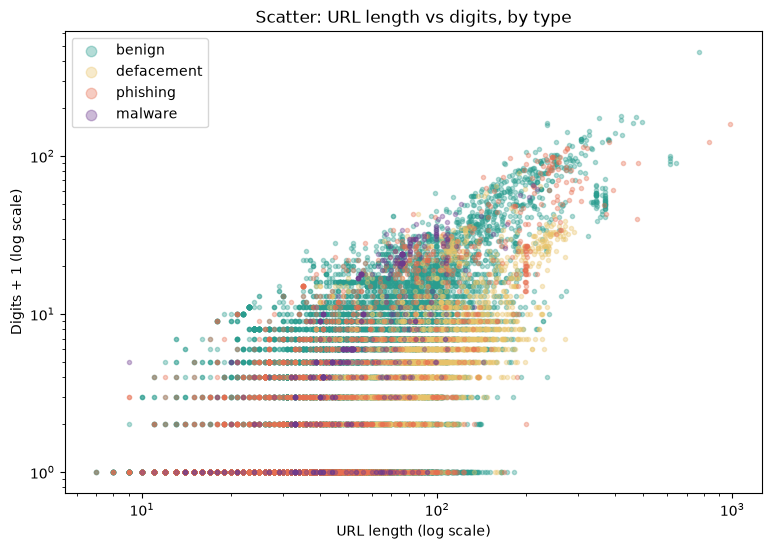

In [17]:
sample = df_cleaned.sample(25000, random_state=42)

plt.figure(figsize=(9, 6))
colors = {'benign': '#2a9d8f', 'defacement': '#e9c46a', 'phishing': '#e76f51', 'malware': '#6d3b8e'}

for t, c in colors.items():
    d = sample[sample['type'] == t]
    plt.scatter(d['url_len'], d['digits'] + 1, s=9, alpha=0.35, color=c, label=t)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('URL length (log scale)')
plt.ylabel('Digits + 1 (log scale)')
plt.title('Scatter: URL length vs digits, by type')
plt.legend(markerscale=2.5)
plt.show()

### Heatmap: correlation between the selected modeling features
Only the selected features are plotted (the label column is excluded because it is a category code, not a measurement).

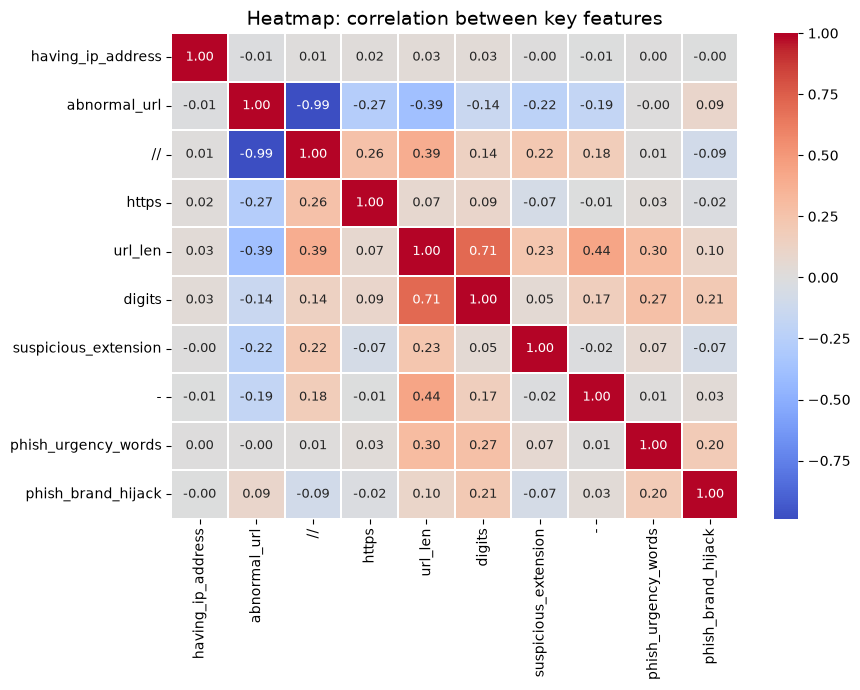

In [25]:
key_features = [c for c in selected_columns if c not in ('type', 'label')]
corr = df_cleaned[key_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 9}, linewidths=0.3)
plt.title('Heatmap: correlation between key features', fontsize=14)
plt.tight_layout()
plt.show()

### Chi-Square Test of Independence: Analyzing URL Features vs. URL Types


In [21]:
# Pick whichever dataframe you have loaded
source_df = df_cleaned if 'df_cleaned' in locals() else df

# 1. Use your REAL column names here:
feature = 'having_ip_address'   # You can also change this to 'https' or 'abnormal_url'
target = 'type'

# 2. Create contingency table
contingency_table = pd.crosstab(source_df[feature], source_df[target])
print("Contingency Table:\n", contingency_table)

# 3. Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# 4. Print results
print("\n--- Chi-Square Test Results ---")
print(f"Chi-square Statistic : {chi2:.4f}")
print(f"p-value               : {p_value:.4e}")
print(f"Degrees of Freedom    : {dof}")

# 5. Interpretation
if p_value < 0.05:
    print(f"\nResult: Significant relationship (Reject H0). '{feature}' and '{target}' are dependent.")
else:
    print(f"\nResult: No significant relationship (Fail to reject H0). '{feature}' and '{target}' are independent.")


Contingency Table:
 type               benign  defacement  malware  phishing
having_ip_address                                       
0                  427202       95308    11845     93155
1                     178           0       21       152

--- Chi-Square Test Results ---
Chi-square Statistic : 291.1787
p-value               : 8.0698e-63
Degrees of Freedom    : 3

Result: Significant relationship (Reject H0). 'having_ip_address' and 'type' are dependent.


### Kruskal-Wallis Test: Analyzing Numerical Features (URL Length & Digits) Across URL Types


In [ ]:
# Select whichever dataframe you have loaded
source_df = df_cleaned if 'df_cleaned' in locals() else df

# Check for both spellings (url_len or urlf_len) and digits
num_cols = ['url_len' if 'url_len' in source_df.columns else 'urlf_len', 'digits']
group_col = 'type'

print("=== Kruskal-Wallis H-Test Results ===")

for col in num_cols:
    if col in source_df.columns:
        # Separate the column values for each group (benign, malware, phishing, defacement)
        groups = [group[col].dropna().values for _, group in source_df.groupby(group_col)]
        
        stat, p_val = kruskal(*groups)
        
        print(f"\n--- Feature: '{col}' across '{group_col}' ---")
        print(f"H-Statistic : {stat:.4f}")
        print(f"p-value     : {p_val:.4e}")
        
        if p_val < 0.05:
            print("Result      : Statistically significant difference between URL types (Reject H0)")
        else:
            print("Result      : No significant difference between URL types (Fail to reject H0)")
    else:
        print(f"\nColumn '{col}' not found in DataFrame.")


=== Kruskal-Wallis H-Test Results ===

--- Feature: 'url_len' across 'type' ---
H-Statistic : 79526.1941
p-value     : 0.0000e+00
Result      : Statistically significant difference between URL types (Reject H0)

--- Feature: 'digits' across 'type' ---
H-Statistic : 21546.7018
p-value     : 0.0000e+00
Result      : Statistically significant difference between URL types (Reject H0)


# Insights from the Malicious URL 

## 1. Dataset and Feature Selection
- The dataset has 651,191 URLs and 64 columns.
- 10 features were selected for modeling: `having_ip_address`, `abnormal_url`, `//`, `https`, `url_len`, `digits`, `suspicious_extension`, `-`, `phish_urgency_words`, `phish_brand_hijack`.
- The target is `label` (0 = benign, 1 = defacement, 2 = phishing, plus malware).

## 2. Data Cleaning
- 12,223 null values were found and removed with `dropna()`.
- 509 duplicate URLs were removed with `drop_duplicates(subset=['url'])`.
- About 627,861 URLs remain after cleaning.

## 3. Overall Statistics
| Statistic | Value |
|-----------|-------|
| Mean | 2.88 |
| Median | 0 |
| Mode | 0 |
| Standard deviation | 21.4 |

- The median and mode are 0, so most feature values are 0.
- The high standard deviation comes from a few large-valued features such as URL length.

## 4. Class Distribution (Bar Chart)
| Type | Count | Share |
|------|-------|-------|
| Benign | ~427k | 68% |
| Defacement | ~95k | 15% |
| Phishing | ~93k | 15% |
| Malware | ~11.9k | 1.9% |

- The data is heavily imbalanced, and malware is the rarest class.

## 5. URL Length vs Type (Line Chart)
- Benign URLs peak at about 30 characters.
- Phishing URLs are mostly under 50 characters.
- Defacement URLs are spread widely from 30 to 150 characters.
- Malware counts are low at every length, with small spikes near 33 and 76.

## 6. Traits by Type (Bar Chart)
| Trait | Highest in | Observation |
|-------|-----------|-------------|
| HTTPS | Malware (~56%) | Phishing ~8%, benign under 1% |
| Suspicious extension | Defacement (~74%) | Benign ~28%, phishing ~29%, malware ~5% |
| Abnormal URL | Benign (~92%) | Phishing ~74%, malware ~10%, defacement ~0% |
| Raw IP address | All near 0% | Very rare in every class |

## 7. URL Length vs Digits (Scatter Plot)
- Digits increase with URL length.
- Malware clusters at mid length with a moderate digit count.
- The classes overlap heavily at low digit counts.

## 8. Correlation Heatmap
- `url_len` and `digits` are strongly correlated (0.71).
- `abnormal_url` and `//` are almost perfectly negatively correlated (-0.99), so they are redundant.
- `url_len` and `-` have a moderate correlation (0.44).
- `phish_urgency_words` and `phish_brand_hijack` correlate only weakly with the other features (0.1 to 0.3).

## 9. Chi-Square Test: `having_ip_address` vs `type`
- χ² = 291.18, df = 3, p ≈ 8e-63, so the feature is significantly related to type.
- Only 351 URLs use a raw IP address.
- Share by type: benign 0.04%, phishing 0.16%, malware 0.18%, defacement 0%.

## 10. Kruskal-Wallis Test: Numeric Features vs Type
| Feature | H-statistic | p-value | Result |
|---------|-------------|---------|--------|
| `url_len` | 79,526.19 | ~0 | Significant difference between types |
| `digits` | 21,546.70 | ~0 | Significant difference between types |

## Summary
- The data is imbalanced, with malware making up under 2%.
- URL length, digits and suspicious extension differ clearly between types.
- HTTPS is most common in malware, and raw IP addresses are rare in every class.
- `abnormal_url` and `//` are redundant.